# Real-Time UPI Fraud Detection
## 02 — Supervised Machine Learning

### Objective
Build and compare supervised classification models to identify potentially fraudulent UPI transactions.

**Models:** Logistic Regression, Random Forest, XGBoost

**Key Challenges:**
- Extreme class imbalance (0.192% fraud)
- Data leakage prevention
- Model evaluation beyond accuracy
- Cost-aware model selection

**Workflow:** Data loading → Splitting → Preprocessing → Baselines → Model training → Imbalance handling → Evaluation → Model selection

**Random Seed:** 42

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

SEED = 42

# Locate the dataset from the repository
data_path = Path("data/upi_eda_ready.csv")

if not data_path.exists():
    data_path = Path("../data/upi_eda_ready.csv")

df = pd.read_csv(
    data_path,
    parse_dates=["timestamp"]
)

print("Dataset shape:", df.shape)
print("Date range:", df["timestamp"].min(), "to", df["timestamp"].max())

print("\nFraud distribution:")
print(df["fraud_flag"].value_counts())

print("\nFraud rate:")
print(f"{df['fraud_flag'].mean() * 100:.4f}%")

assert df["fraud_flag"].isin([0, 1]).all()
assert df["transaction id"].is_unique

display(df.head())

Dataset shape: (250000, 18)
Date range: 2024-01-01 00:05:10 to 2024-12-30 23:55:40

Fraud distribution:
fraud_flag
0    249520
1       480
Name: count, dtype: int64

Fraud rate:
0.1920%


,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend,month
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0,10
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0,4
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0,4
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0,1


## Chronological Train / Validation / Test Split

Transactions are sorted by timestamp to simulate real-world fraud detection.

- Training: Oldest 70% of transactions
- Validation: Next 15% of transactions
- Testing: Latest 15% of transactions

We will examine fraud counts, fraud rates, and date boundaries before finalizing the split.

In [18]:
# Sort transactions chronologically
df_sorted = df.sort_values(
    ["timestamp", "transaction id"]
).reset_index(drop=True)

# Split boundaries
n = len(df_sorted)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Create chronological partitions
train_df = df_sorted.iloc[:train_end].copy()
val_df = df_sorted.iloc[train_end:val_end].copy()
test_df = df_sorted.iloc[val_end:].copy()

# Summarize each partition
split_summary = []

for name, subset in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    split_summary.append({
        "Split": name,
        "Transactions": len(subset),
        "Genuine": (subset["fraud_flag"] == 0).sum(),
        "Fraud": (subset["fraud_flag"] == 1).sum(),
        "Fraud Rate (%)": round(
            subset["fraud_flag"].mean() * 100, 4
        ),
        "Start Date": subset["timestamp"].min(),
        "End Date": subset["timestamp"].max()
    })

split_summary = pd.DataFrame(split_summary)

display(split_summary)

print("Total transactions:", split_summary["Transactions"].sum())
print("Total frauds:", split_summary["Fraud"].sum())

,Split,Transactions,Genuine,Fraud,Fraud Rate (%),Start Date,End Date
0,Train,175000,174675,325,0.1857,2024-01-01 00:05:10,2024-09-12 17:03:58
1,Validation,37500,37412,88,0.2347,2024-09-12 17:04:19,2024-11-06 07:06:12
2,Test,37500,37433,67,0.1787,2024-11-06 07:09:06,2024-12-30 23:55:40


Total transactions: 250000
Total frauds: 480


### Final Splitting Decision: Chronological 70/15/15

We selected chronological splitting to simulate real-world
fraud detection using historical transactions.

| Split | Transactions | Fraud | Fraud Rate |
|---|---:|---:|---:|
| Train | 175,000 | 325 | 0.1857% |
| Validation | 37,500 | 88 | 0.2347% |
| Test | 37,500 | 67 | 0.1787% |

**Decision:** Accept the chronological split.

- No random shuffling was applied.
- Every partition contains genuine and fraudulent transactions.
- SMOTE and other learned transformations will use training data only.
- Validation will support model selection and threshold tuning.
- Test data will remain untouched until final evaluation.

The same partitions will be shared with the anomaly detection team.

In [19]:
from pathlib import Path

# Confirm unique, non-overlapping partitions
train_ids = set(train_df["transaction id"])
val_ids = set(val_df["transaction id"])
test_ids = set(test_df["transaction id"])

assert not train_ids & val_ids
assert not train_ids & test_ids
assert not val_ids & test_ids

assert len(train_ids | val_ids | test_ids) == len(df)

assert train_df["timestamp"].max() < val_df["timestamp"].min()
assert val_df["timestamp"].max() < test_df["timestamp"].min()

# Save the shared split mapping
split_mapping = pd.concat([
    train_df[["transaction id"]].assign(split="train"),
    val_df[["transaction id"]].assign(split="validation"),
    test_df[["transaction id"]].assign(split="test")
])

output_dir = Path("../data") if Path("../data").exists() else Path("data")
output_dir.mkdir(parents=True, exist_ok=True)

split_mapping.to_csv(
    output_dir / "upi_split_mapping.csv",
    index=False
)

print("Chronological split validated successfully!")
print(split_mapping["split"].value_counts())

Chronological split validated successfully!
split
train         175000
validation     37500
test           37500
Name: count, dtype: int64


In [20]:
# Define feature groups

numeric_features = [
    "amount (INR)",
    "hour_of_day",
    "month"
]

categorical_features = [
    "transaction type",
    "merchant_category",
    "sender_age_group",
    "receiver_age_group",
    "sender_state",
    "sender_bank",
    "receiver_bank",
    "device_type",
    "network_type",
    "day_of_week"
]

binary_features = [
    "is_weekend"
]

feature_cols = (
    numeric_features +
    categorical_features +
    binary_features
)

target_col = "fraud_flag"

# Validate feature configuration
assert len(feature_cols) == 14
assert len(feature_cols) == len(set(feature_cols))
assert all(col in df.columns for col in feature_cols)

# Prepare X and y for each chronological partition
X_train = train_df[feature_cols].copy()
X_val = val_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_df[target_col].copy()
y_val = val_df[target_col].copy()
y_test = test_df[target_col].copy()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Binary features:", len(binary_features))

print("\nDataset shapes:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)

Numerical features: 3
Categorical features: 10
Binary features: 1

Dataset shapes:
X_train: (175000, 14) y_train: (175000,)
X_val:   (37500, 14) y_val:   (37500,)
X_test:  (37500, 14) y_test:  (37500,)


In [21]:
# Calculate high-amount threshold from training data only
Q1 = X_train["amount (INR)"].quantile(0.25)
Q3 = X_train["amount (INR)"].quantile(0.75)

high_amount_threshold = Q3 + 1.5 * (Q3 - Q1)

print("Training-only high amount threshold:",
      high_amount_threshold)


def engineer_features(X, threshold):
    X = X.copy()

    # 1. Log transformation
    X["log_amount"] = np.log1p(X["amount (INR)"])

    # 2. High amount indicator
    X["is_high_amount"] = (
        X["amount (INR)"] > threshold
    ).astype(int)

    # 3. Cyclical hour encoding
    X["hour_sin"] = np.sin(
        2 * np.pi * X["hour_of_day"] / 24
    )

    X["hour_cos"] = np.cos(
        2 * np.pi * X["hour_of_day"] / 24
    )

    # 4. Same-bank indicator
    X["same_bank"] = (
        X["sender_bank"] == X["receiver_bank"]
    ).astype(int)

    return X


# Engineer features separately for each partition
X_train_fe = engineer_features(
    X_train, high_amount_threshold
)

X_val_fe = engineer_features(
    X_val, high_amount_threshold
)

X_test_fe = engineer_features(
    X_test, high_amount_threshold
)

print("Baseline shape:", X_train.shape)
print("Engineered shape:", X_train_fe.shape)

display(
    X_train_fe[
        [
            "amount (INR)",
            "log_amount",
            "is_high_amount",
            "hour_sin",
            "hour_cos",
            "same_bank"
        ]
    ].head()
)

Training-only high amount threshold: 3551.5
Baseline shape: (175000, 14)
Engineered shape: (175000, 19)


,amount (INR),log_amount,is_high_amount,hour_sin,hour_cos,same_bank
0,1540,7.340187,0,0.0,1.0,0
1,1438,7.271704,0,0.0,1.0,0
2,394,5.978886,0,0.0,1.0,0
3,1716,7.448334,0,0.0,1.0,0
4,439,6.086775,0,0.0,1.0,0


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Original feature groups
numeric_features = [
    "amount (INR)",
    "hour_of_day",
    "month"
]

categorical_features = [
    "transaction type",
    "merchant_category",
    "sender_age_group",
    "receiver_age_group",
    "sender_state",
    "sender_bank",
    "receiver_bank",
    "device_type",
    "network_type",
    "day_of_week"
]

binary_features = ["is_weekend"]

# Engineered feature groups
engineered_numeric = [
    "log_amount",
    "hour_sin",
    "hour_cos"
]

engineered_binary = [
    "is_high_amount",
    "same_bank"
]


def build_preprocessor(use_engineered=False):

    num_cols = numeric_features.copy()
    bin_cols = binary_features.copy()

    if use_engineered:
        num_cols += engineered_numeric
        bin_cols += engineered_binary

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        ))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_pipeline, num_cols),
            ("cat", categorical_pipeline, categorical_features),
            ("bin", "passthrough", bin_cols)
        ],
        sparse_threshold=1.0
    )

    return preprocessor


baseline_preprocessor = build_preprocessor(False)
engineered_preprocessor = build_preprocessor(True)

print("Baseline preprocessor configured.")
print("Engineered preprocessor configured.")

Baseline preprocessor configured.
Engineered preprocessor configured.


In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

# Baseline Logistic Regression pipeline
lr_baseline = Pipeline([
    ("preprocessing", build_preprocessor(False)),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=SEED
    ))
])

# Train only on historical training data
lr_baseline.fit(X_train, y_train)

# Predict fraud probabilities on validation data
val_prob = lr_baseline.predict_proba(X_val)[:, 1]

# Convert probabilities to class predictions
val_pred = (val_prob >= 0.5).astype(int)

# Evaluation
results = {
    "Accuracy": accuracy_score(y_val, val_pred),
    "Precision": precision_score(
        y_val, val_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, val_pred),
    "F1 Score": f1_score(y_val, val_pred),
    "PR-AUC (AP)": average_precision_score(y_val, val_prob),
    "ROC-AUC": roc_auc_score(y_val, val_prob)
}

print("Logistic Regression — Baseline Results")
display(
    pd.DataFrame([results]).round(4)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_pred))

print("\nPredicted fraud cases:", val_pred.sum())
print("Actual fraud cases:", y_val.sum())

Logistic Regression — Baseline Results


,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
0,0.9977,0.0,0.0,0.0,0.005,0.5215



Confusion Matrix:
[[37412     0]
 [   88     0]]

Predicted fraud cases: 0
Actual fraud cases: 88


### Finding: Logistic Regression Baseline

The baseline model achieved 99.77% accuracy but
failed to identify any of the 88 fraudulent transactions.

- Precision: 0
- Recall: 0
- F1-score: 0
- Average Precision: 0.0050
- ROC-AUC: 0.5215

**Conclusion:** High accuracy is misleading under severe
class imbalance. The model's probability ranking is weak,
and a fixed threshold of 0.5 produces no fraud detections.

Next, evaluate class weighting while keeping the same
chronological training and validation partitions.

In [24]:
# Logistic Regression with balanced class weights

lr_weighted = Pipeline([
    ("preprocessing", build_preprocessor(False)),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=SEED
    ))
])

lr_weighted.fit(X_train, y_train)

weighted_prob = lr_weighted.predict_proba(X_val)[:, 1]
weighted_pred = (weighted_prob >= 0.5).astype(int)

weighted_results = {
    "Accuracy": accuracy_score(y_val, weighted_pred),
    "Precision": precision_score(
        y_val, weighted_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, weighted_pred),
    "F1 Score": f1_score(y_val, weighted_pred),
    "PR-AUC (AP)": average_precision_score(
        y_val, weighted_prob
    ),
    "ROC-AUC": roc_auc_score(y_val, weighted_prob)
}

comparison = pd.DataFrame(
    [results, weighted_results],
    index=["LR Baseline", "LR Class Weighted"]
)

display(comparison.round(4))

print("Weighted Confusion Matrix:")
print(confusion_matrix(y_val, weighted_pred))

print("Predicted fraud cases:", weighted_pred.sum())

,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
LR Baseline,0.9977,0.0000,0.0000,0.0000,0.0050,0.5215
LR Class Weighted,0.7123,0.0022,0.2727,0.0044,0.0034,0.5099


Weighted Confusion Matrix:
[[26688 10724]
 [   64    24]]
Predicted fraud cases: 10748


### Finding: Logistic Regression with Class Weights

Class weighting increased fraud recall from 0% to 27.27%.

However:
- Only 24 of 88 frauds were detected.
- 10,724 genuine transactions were incorrectly flagged.
- Precision remained extremely low (0.22%).
- Average Precision decreased from 0.0050 to 0.0034.

**Conclusion:** Class weighting improves fraud detection at
the 0.5 threshold but produces too many false positives.
It does not improve overall ranking performance.

Further experiments with feature engineering, SMOTE,
and alternative classifiers are required.

In [25]:
# Logistic Regression with engineered features

lr_engineered = Pipeline([
    ("preprocessing", build_preprocessor(True)),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=SEED
    ))
])

lr_engineered.fit(X_train_fe, y_train)

engineered_prob = lr_engineered.predict_proba(X_val_fe)[:, 1]
engineered_pred = (engineered_prob >= 0.5).astype(int)

engineered_results = {
    "Accuracy": accuracy_score(y_val, engineered_pred),
    "Precision": precision_score(
        y_val, engineered_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, engineered_pred),
    "F1 Score": f1_score(y_val, engineered_pred),
    "PR-AUC (AP)": average_precision_score(
        y_val, engineered_prob
    ),
    "ROC-AUC": roc_auc_score(y_val, engineered_prob)
}

comparison = pd.DataFrame(
    [results, weighted_results, engineered_results],
    index=[
        "LR Baseline",
        "LR Class Weighted",
        "LR Engineered"
    ]
)

display(comparison.round(4))

print("Engineered Confusion Matrix:")
print(confusion_matrix(y_val, engineered_pred))

,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
LR Baseline,0.9977,0.0000,0.0000,0.0000,0.0050,0.5215
LR Class Weighted,0.7123,0.0022,0.2727,0.0044,0.0034,0.5099
LR Engineered,0.9977,0.0000,0.0000,0.0000,0.0043,0.5171


Engineered Confusion Matrix:
[[37412     0]
 [   88     0]]


### Finding: Logistic Regression Feature Engineering

Adding five engineered features did not improve the
Logistic Regression model.

- Baseline AP: 0.0050
- Engineered AP: 0.0043
- Both models detected zero fraud at threshold 0.5.

**Conclusion:** The engineered features did not improve
validation performance for Logistic Regression.

Next, evaluate more flexible classifiers and compare
imbalance-handling strategies.

In [26]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest baseline
rf_baseline = Pipeline([
    ("preprocessing", build_preprocessor(False)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=SEED
    ))
])

# Train on chronological training data
rf_baseline.fit(X_train, y_train)

# Validation probabilities and predictions
rf_prob = rf_baseline.predict_proba(X_val)[:, 1]
rf_pred = (rf_prob >= 0.5).astype(int)

rf_results = {
    "Accuracy": accuracy_score(y_val, rf_pred),
    "Precision": precision_score(y_val, rf_pred, zero_division=0),
    "Recall": recall_score(y_val, rf_pred),
    "F1 Score": f1_score(y_val, rf_pred),
    "PR-AUC (AP)": average_precision_score(y_val, rf_prob),
    "ROC-AUC": roc_auc_score(y_val, rf_prob)
}

comparison = pd.DataFrame(
    [results, weighted_results, engineered_results, rf_results],
    index=[
        "LR Baseline",
        "LR Class Weighted",
        "LR Engineered",
        "RF Baseline"
    ]
)

display(comparison.round(4))

print("\nRandom Forest Confusion Matrix:")
print(confusion_matrix(y_val, rf_pred))

print("\nPredicted fraud cases:", rf_pred.sum())
print("Actual fraud cases:", y_val.sum())

,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
LR Baseline,0.9977,0.0000,0.0000,0.0000,0.0050,0.5215
LR Class Weighted,0.7123,0.0022,0.2727,0.0044,0.0034,0.5099
LR Engineered,0.9977,0.0000,0.0000,0.0000,0.0043,0.5171
RF Baseline,0.9977,0.0000,0.0000,0.0000,0.0030,0.5453



Random Forest Confusion Matrix:
[[37412     0]
 [   88     0]]

Predicted fraud cases: 0
Actual fraud cases: 88


### Finding: Random Forest Baseline

Random Forest achieved 99.77% accuracy but detected
none of the 88 fraudulent validation transactions.

- Recall: 0%
- Average Precision: 0.0030
- ROC-AUC: 0.5453

**Conclusion:** Random Forest provides slightly better
ROC-AUC than Logistic Regression, but worse AP.

The model's ranking ability remains weak, and its
0.5 classification threshold is unsuitable for fraud detection.

Next, evaluate Random Forest with class weighting.

In [27]:
# Random Forest with class weighting

rf_weighted = Pipeline([
    ("preprocessing", build_preprocessor(False)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        n_jobs=-1,
        random_state=SEED
    ))
])

rf_weighted.fit(X_train, y_train)

# Validation predictions
rf_weighted_prob = rf_weighted.predict_proba(X_val)[:, 1]
rf_weighted_pred = (rf_weighted_prob >= 0.5).astype(int)

rf_weighted_results = {
    "Accuracy": accuracy_score(y_val, rf_weighted_pred),
    "Precision": precision_score(
        y_val, rf_weighted_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, rf_weighted_pred),
    "F1 Score": f1_score(y_val, rf_weighted_pred),
    "PR-AUC (AP)": average_precision_score(
        y_val, rf_weighted_prob
    ),
    "ROC-AUC": roc_auc_score(y_val, rf_weighted_prob)
}

comparison = pd.DataFrame(
    [rf_results, rf_weighted_results],
    index=["RF Baseline", "RF Class Weighted"]
)

display(comparison.round(4))

print("\nWeighted Random Forest Confusion Matrix:")
print(confusion_matrix(y_val, rf_weighted_pred))

print("\nPredicted fraud cases:", rf_weighted_pred.sum())

,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
RF Baseline,0.9977,0.0,0.0,0.0,0.0030,0.5453
RF Class Weighted,0.9976,0.0,0.0,0.0,0.0029,0.5046



Weighted Random Forest Confusion Matrix:
[[37410     2]
 [   88     0]]

Predicted fraud cases: 2


### Finding: Random Forest with Class Weighting

Class weighting did not improve Random Forest performance.

- Baseline recall: 0%
- Weighted recall: 0%
- Weighted model flagged 2 transactions, both genuine.
- Average Precision decreased from 0.0030 to 0.0029.
- ROC-AUC decreased from 0.5453 to 0.5046.

**Conclusion:** Class weighting alone is insufficient.
We need to compare additional algorithms, imbalance
handling techniques and decision thresholds.

In [28]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
from xgboost import XGBClassifier

# XGBoost baseline
xgb_baseline = Pipeline([
    ("preprocessing", build_preprocessor(False)),
    ("model", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=SEED,
        n_jobs=-1
    ))
])

xgb_baseline.fit(X_train, y_train)

# Validation probabilities
xgb_prob = xgb_baseline.predict_proba(X_val)[:, 1]
xgb_pred = (xgb_prob >= 0.5).astype(int)

xgb_results = {
    "Accuracy": accuracy_score(y_val, xgb_pred),
    "Precision": precision_score(y_val, xgb_pred, zero_division=0),
    "Recall": recall_score(y_val, xgb_pred),
    "F1 Score": f1_score(y_val, xgb_pred),
    "PR-AUC (AP)": average_precision_score(y_val, xgb_prob),
    "ROC-AUC": roc_auc_score(y_val, xgb_prob)
}

comparison = pd.DataFrame(
    [results, rf_results, xgb_results],
    index=["LR Baseline", "RF Baseline", "XGB Baseline"]
)

display(comparison.round(5))

print("\nXGBoost Confusion Matrix:")
print(confusion_matrix(y_val, xgb_pred))

print("\nPredicted fraud:", xgb_pred.sum())
print("Actual fraud:", y_val.sum())

,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
LR Baseline,0.99765,0.0,0.0,0.0,0.00498,0.52146
RF Baseline,0.99765,0.0,0.0,0.0,0.00301,0.54532
XGB Baseline,0.99765,0.0,0.0,0.0,0.00334,0.54243



XGBoost Confusion Matrix:
[[37412     0]
 [   88     0]]

Predicted fraud: 0
Actual fraud: 88


In [30]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

# Separate feature groups for the engineered dataset
num_cols = [
    "amount (INR)", "hour_of_day", "month",
    "log_amount", "hour_sin", "hour_cos"
]

cat_cols = [
    "transaction type", "merchant_category",
    "sender_age_group", "receiver_age_group",
    "sender_state", "sender_bank", "receiver_bank",
    "device_type", "network_type", "day_of_week"
]

bin_cols = ["is_weekend", "is_high_amount", "same_bank"]

# 1. Prepare data for SMOTENC:
# Encode categories as integer codes rather than one-hot vectors.
smote_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), cat_cols),
    ("bin", "passthrough", bin_cols)
])

categorical_indices = list(range(
    len(num_cols),
    len(num_cols) + len(cat_cols) + len(bin_cols)
))

# 2. Define SMOTE for mixed data
smote = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=0.05,
    random_state=SEED,
    k_neighbors=5
)

# 3. Re-encode categorical features after SMOTE
post_smote_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), list(range(len(num_cols)))),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_indices)
])

# 4. Build complete training pipeline
lr_smote = ImbPipeline([
    ("pre_smote", smote_preprocessor),
    ("smote", smote),
    ("post_smote", post_smote_preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=SEED
    ))
])

# Train only using training data
lr_smote.fit(X_train_fe, y_train)

# Evaluate on untouched validation data
smote_prob = lr_smote.predict_proba(X_val_fe)[:, 1]
smote_pred = (smote_prob >= 0.5).astype(int)

smote_results = {
    "Accuracy": accuracy_score(y_val, smote_pred),
    "Precision": precision_score(
        y_val, smote_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, smote_pred),
    "F1 Score": f1_score(y_val, smote_pred),
    "PR-AUC (AP)": average_precision_score(y_val, smote_prob),
    "ROC-AUC": roc_auc_score(y_val, smote_prob)
}

display(pd.DataFrame(
    [results, engineered_results, smote_results],
    index=["LR Baseline", "LR Engineered", "LR SMOTENC + Engineered"]
).round(5))

print("\nSMOTENC Confusion Matrix:")
print(confusion_matrix(y_val, smote_pred))
print("Predicted fraud:", smote_pred.sum())

,Accuracy,Precision,Recall,F1 Score,PR-AUC (AP),ROC-AUC
LR Baseline,0.99765,0.0,0.0,0.0,0.00498,0.52146
LR Engineered,0.99765,0.0,0.0,0.0,0.00425,0.51709
LR SMOTENC + Engineered,0.99763,0.0,0.0,0.0,0.00276,0.53058



SMOTENC Confusion Matrix:
[[37411     1]
 [   88     0]]
Predicted fraud: 1


### Finding: SMOTENC with Engineered Features

SMOTENC was applied only to the training dataset,
using a minority-to-majority ratio of 0.05.

Results:
- Recall: 0%
- Average Precision: 0.00276
- ROC-AUC: 0.53058
- False positives: 1
- Fraud detected: 0 of 88

**Conclusion:** This SMOTENC configuration did not improve
Logistic Regression's fraud detection performance.

The default 0.5 threshold may be unsuitable, and the
available features appear to contain limited fraud signal.

In [32]:
# Examine predicted fraud probability distributions

probability_summary = pd.DataFrame({
    "LR Baseline": val_prob,
    "LR Weighted": weighted_prob,
    "LR Engineered": engineered_prob,
    "RF Baseline": rf_prob,
    "RF Weighted": rf_weighted_prob,
    "XGBoost": xgb_prob,
    "LR SMOTENC": smote_prob
})

display(
    probability_summary.describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    ).round(6)
)

print("\nMaximum probability by model:")
display(probability_summary.max().sort_values(ascending=False))

# Compare scores for genuine and fraudulent transactions
fraud_probability_comparison = pd.DataFrame({
    "Actual Fraud": y_val.to_numpy(),
    "LR Baseline": val_prob,
    "XGBoost": xgb_prob,
    "LR SMOTENC": smote_prob
})

display(
    fraud_probability_comparison
    .groupby("Actual Fraud")
    .agg(["mean", "median", "max"])
    .round(6)
)

,LR Baseline,LR Weighted,LR Engineered,RF Baseline,RF Weighted,XGBoost,LR SMOTENC
count,37500.000000,37500.000000,37500.000000,37500.000000,37500.000000,37500.000000,37500.000000
mean,0.001569,0.441410,0.001599,0.001921,0.218670,0.001130,0.031741
std,0.000628,0.101913,0.000683,0.001673,0.055405,0.000699,0.040744
min,0.000409,0.120405,0.000371,0.000229,0.042231,0.000170,0.000003
50%,0.001468,0.440662,0.001490,0.001294,0.217396,0.000958,0.016529
90%,0.002344,0.575321,0.002402,0.004005,0.289855,0.001931,0.081924
95%,0.002685,0.610878,0.002764,0.005230,0.311471,0.002378,0.113969
99%,0.003543,0.676685,0.003661,0.008411,0.352466,0.003744,0.190196
max,0.013766,0.858563,0.025337,0.028593,0.523050,0.015400,0.561778



Maximum probability by model:


LR Weighted      0.858563
LR SMOTENC       0.561778
RF Weighted      0.523050
RF Baseline      0.028593
LR Engineered    0.025337
XGBoost          0.015400
LR Baseline      0.013766
dtype: float64

LR Baseline                       XGBoost                      \
                    mean    median       max      mean    median       max   
Actual Fraud                                                                 
0               0.001569  0.001467  0.013766  0.001130  0.000958  0.015400   
1               0.001685  0.001529  0.009287  0.001229  0.001098  0.007398   

             LR SMOTENC                      
                   mean    median       max  
Actual Fraud                                 
0              0.031730  0.016518  0.561778  
1              0.036334  0.021316  0.177782

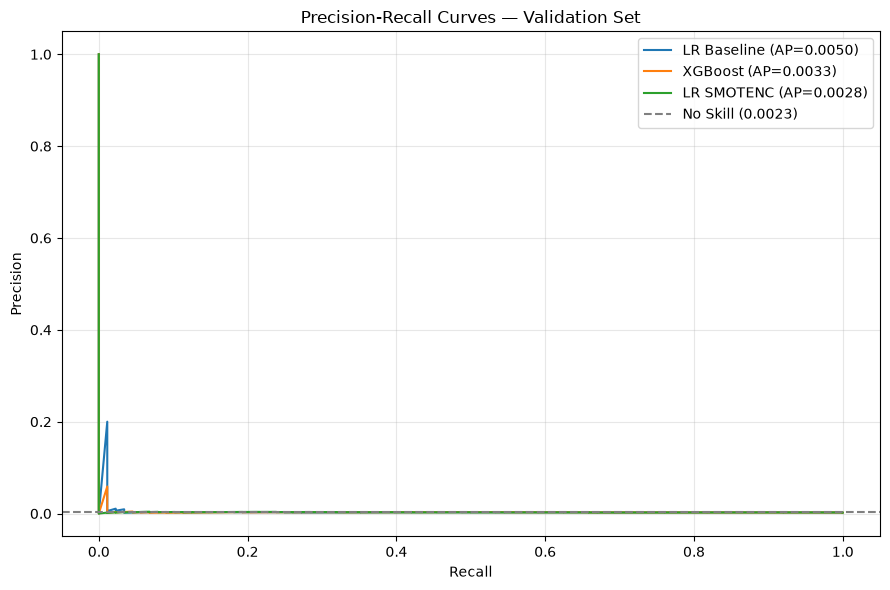

In [33]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

models_to_compare = {
    "LR Baseline": val_prob,
    "XGBoost": xgb_prob,
    "LR SMOTENC": smote_prob
}

plt.figure(figsize=(9, 6))

for name, probabilities in models_to_compare.items():

    precision, recall, thresholds = precision_recall_curve(
        y_val, probabilities
    )

    ap = average_precision_score(y_val, probabilities)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP={ap:.4f})"
    )

# No-skill baseline
baseline_rate = y_val.mean()

plt.axhline(
    baseline_rate,
    linestyle="--",
    color="gray",
    label=f"No Skill ({baseline_rate:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves — Validation Set")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()